In [45]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Membaca dataset
df = pd.read_csv("credit_card_fraud_10k.csv")

# Menampilkan 5 data pertama
df.head()

,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


In [46]:
# Menampilkan informasi dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       10000 non-null  int64  
 1   amount               10000 non-null  float64
 2   transaction_hour     10000 non-null  int64  
 3   merchant_category    10000 non-null  str    
 4   foreign_transaction  10000 non-null  int64  
 5   location_mismatch    10000 non-null  int64  
 6   device_trust_score   10000 non-null  int64  
 7   velocity_last_24h    10000 non-null  int64  
 8   cardholder_age       10000 non-null  int64  
 9   is_fraud             10000 non-null  int64  
dtypes: float64(1), int64(8), str(1)
memory usage: 781.4 KB


In [47]:
# Menampilkan statistik deskriptif
df.describe(include="all")

,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
count,10000.00000,10000.000000,10000.000000,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
unique,NaN,NaN,NaN,5,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,Food,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,2093,NaN,NaN,NaN,NaN,NaN,NaN
mean,5000.50000,175.949849,11.593300,NaN,0.097800,0.085700,61.798900,2.008900,43.468700,0.015100
std,2886.89568,175.392827,6.922708,NaN,0.297059,0.279935,21.487053,1.432559,14.979147,0.121957
min,1.00000,0.000000,0.000000,NaN,0.000000,0.000000,25.000000,0.000000,18.000000,0.000000
25%,2500.75000,50.905000,6.000000,NaN,0.000000,0.000000,43.000000,1.000000,30.000000,0.000000
50%,5000.50000,122.095000,12.000000,NaN,0.000000,0.000000,62.000000,2.000000,44.000000,0.000000
75%,7500.25000,242.480000,18.000000,NaN,0.000000,0.000000,80.000000,3.000000,56.000000,0.000000


In [48]:
# Memeriksa jumlah nilai kosong di setiap kolom
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

Series([], dtype: int64)

In [49]:
# Memeriksa kolom dengan missing values kurang dari 1000
less = missing_values[missing_values < 1000].index

# Memeriksa kolom dengan missing values 1000 atau lebih
over = missing_values[missing_values >= 1000].index

In [50]:
# Memilih kolom numerik
numeric_features = df[less].select_dtypes(
    include=["number"]
).columns

# Mengisi nilai kosong dengan median
df[numeric_features] = df[numeric_features].fillna(
    df[numeric_features].median()
)

In [51]:
# Memilih kolom kategori
categorical_features = df[less].select_dtypes(
    include=["object", "str", "string"]
).columns

# Mengisi nilai kosong dengan modus
for column in categorical_features:
    if df[column].isnull().any():
        df[column] = df[column].fillna(
            df[column].mode()[0]
        )

In [52]:
# Menghapus kolom yang memiliki missing values 1000 atau lebih
df = df.drop(columns=over)

# Menampilkan data
df.head()

,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


In [53]:
# Memeriksa nilai kosong setelah preprocessing
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

Series([], dtype: int64)

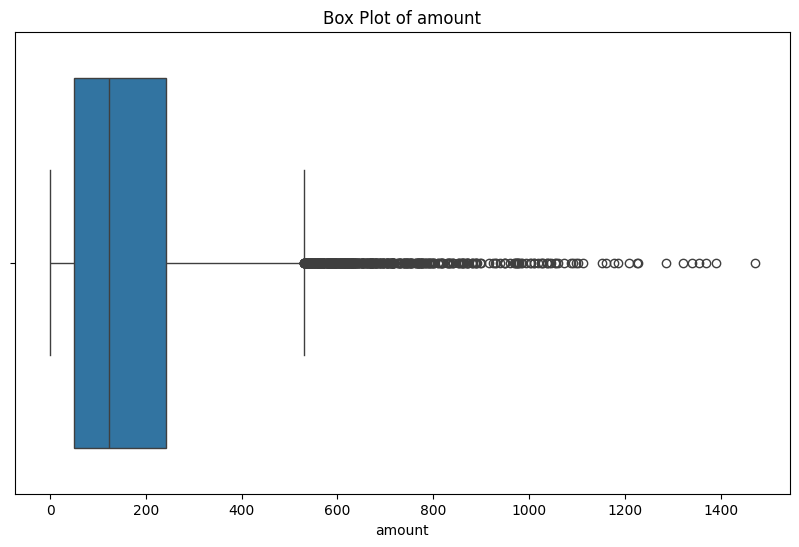

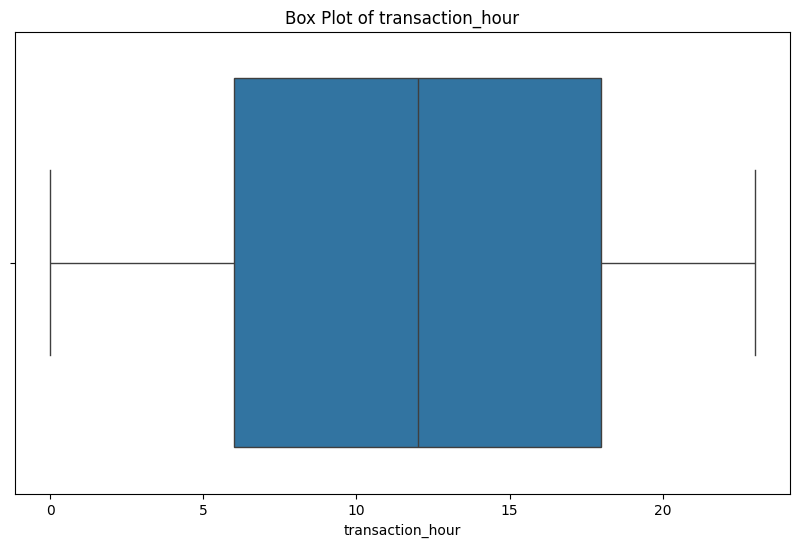

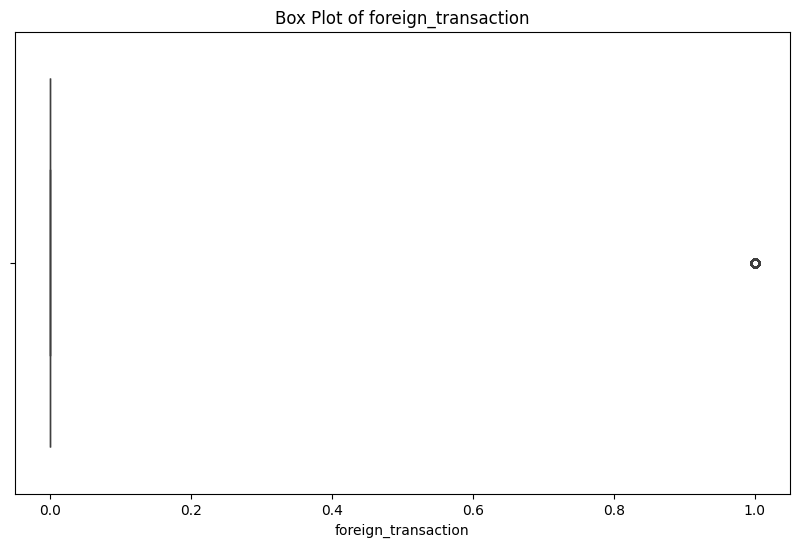

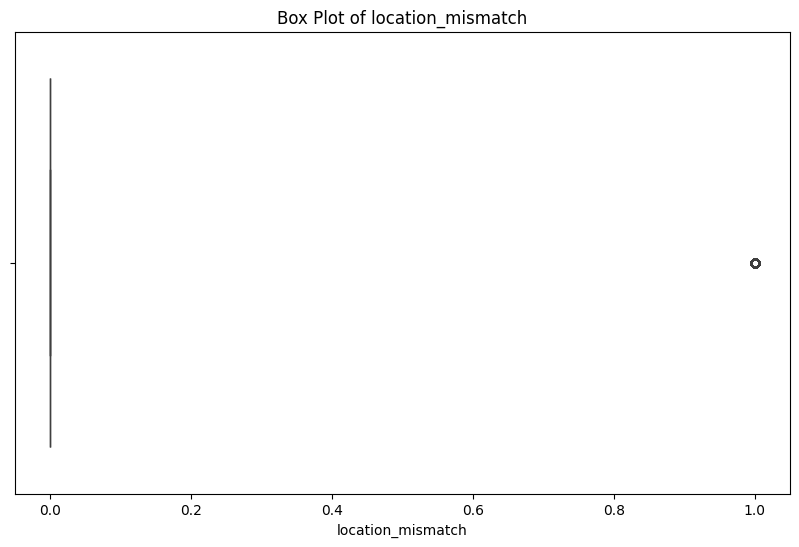

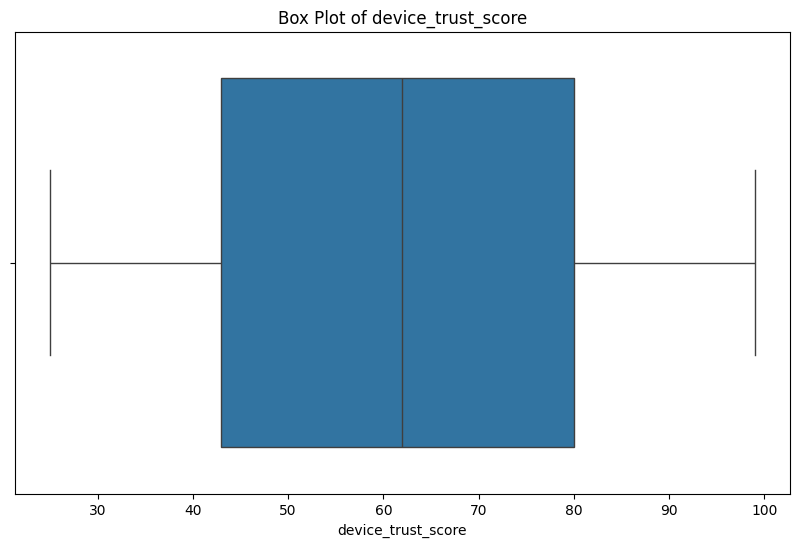

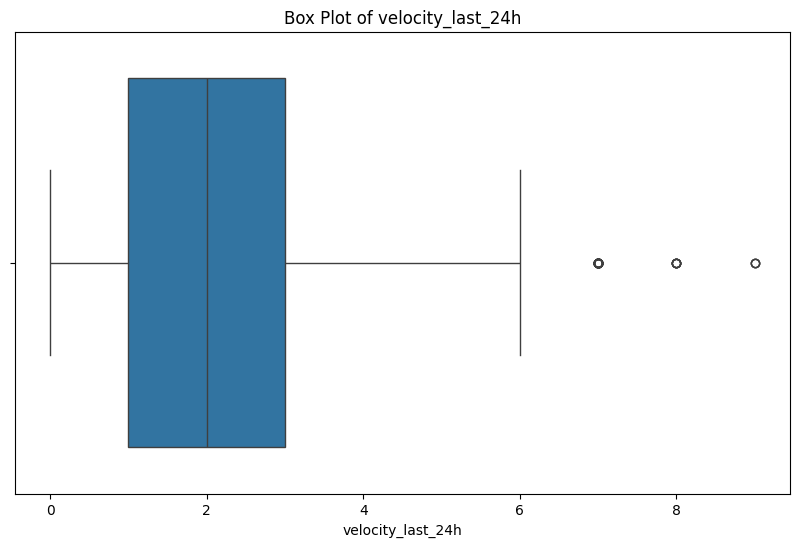

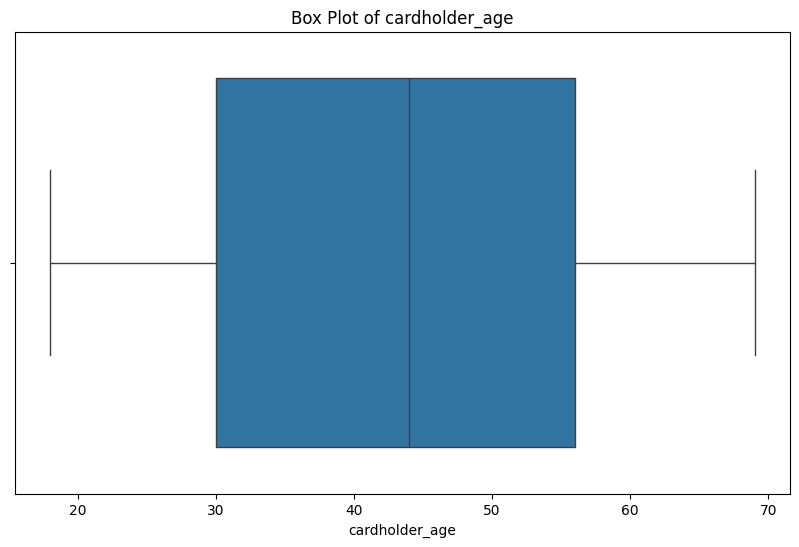

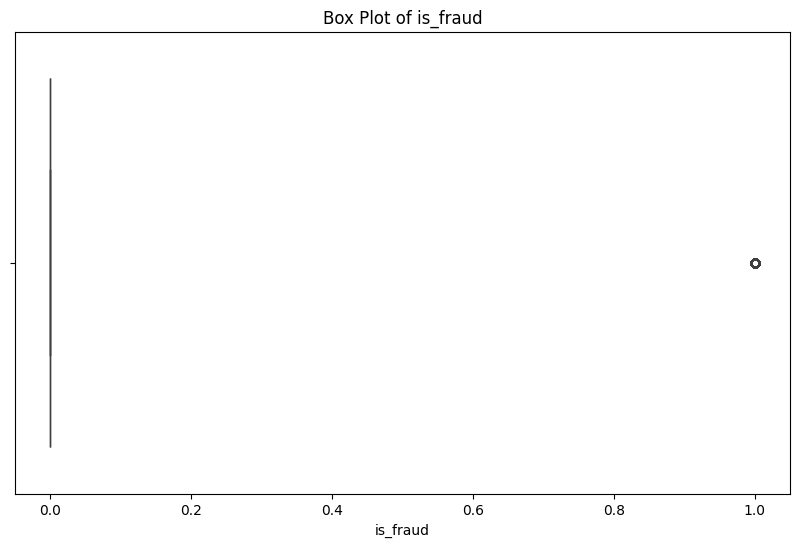

In [54]:
# Memilih kolom numerik
numeric_features = df.select_dtypes(
    include=["number"]
).columns

# Menghapus transaction_id dari daftar fitur
numeric_features = numeric_features.drop(
    "transaction_id", errors="ignore"
)

# Membuat box plot
for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f"Box Plot of {feature}")
    plt.show()

In [55]:
# Menghitung Q1 dan Q3
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)

# Menghitung IQR
IQR = Q3 - Q1

# Menentukan batas bawah dan batas atas
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

# Menghitung jumlah outlier pada setiap kolom
outlier_condition = (
    (df[numeric_features] < batas_bawah) |
    (df[numeric_features] > batas_atas)
)

outlier_condition.sum()

amount                 501
transaction_hour         0
foreign_transaction    978
location_mismatch      857
device_trust_score       0
velocity_last_24h       51
cardholder_age           0
is_fraud               151
dtype: int64

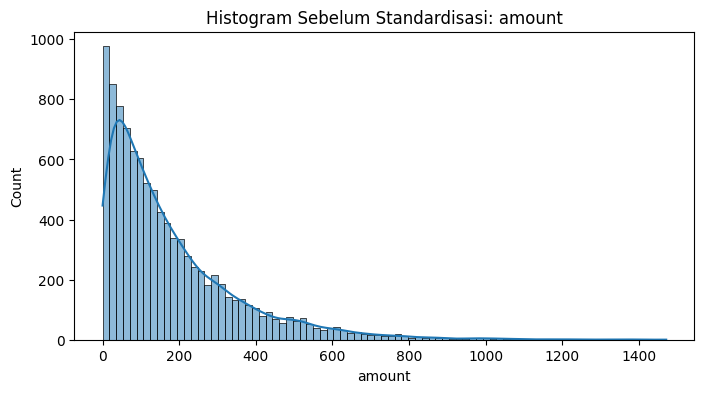

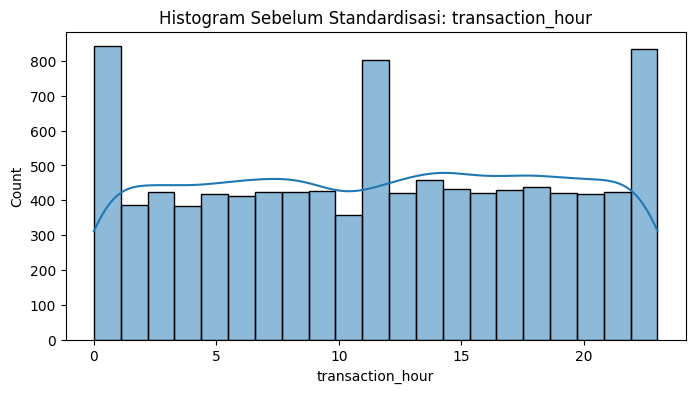

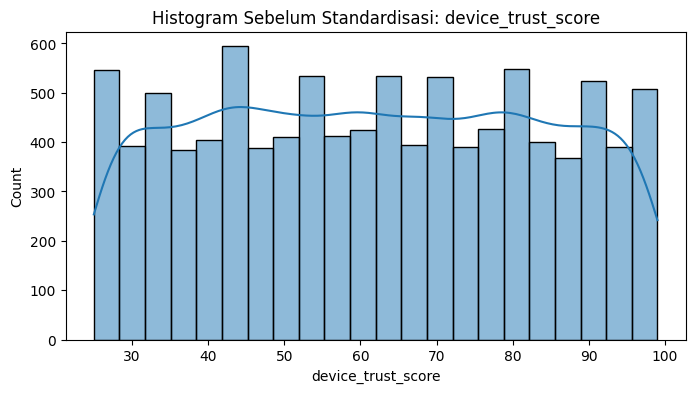

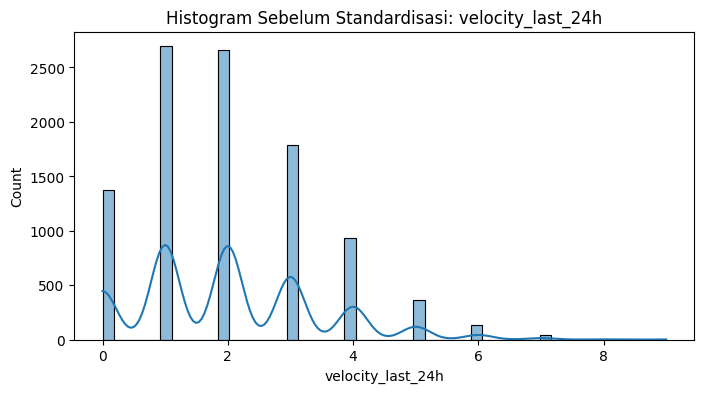

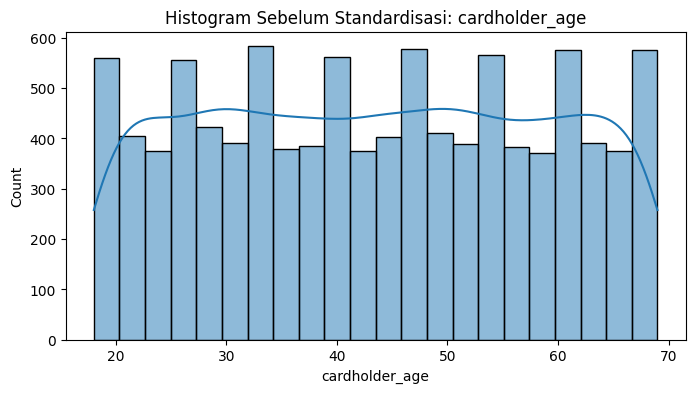

In [56]:
# Memilih beberapa kolom numerik
columns_to_plot = [
    "amount",
    "transaction_hour",
    "device_trust_score",
    "velocity_last_24h",
    "cardholder_age"
]

# Membuat histogram
for column in columns_to_plot:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[column], kde=True)
    plt.title(f"Histogram Sebelum Standardisasi: {column}")
    plt.show()

In [57]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Jumlah baris duplikat:", duplicates.sum())

# Menampilkan baris duplikat
df[duplicates]

Jumlah baris duplikat: 0


,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud


In [58]:
# Menghapus data duplikat
df = df.drop_duplicates()

print("Data setelah menghapus duplikat:")
print(df.shape)

Data setelah menghapus duplikat:
(10000, 10)


In [59]:
# Memilih kolom kategori
category_features = df.select_dtypes(
    include=["object", "str", "string"]
).columns

# Menampilkan data kategori
df[category_features].head()

,merchant_category
0,Electronics
1,Travel
2,Grocery
3,Grocery
4,Food


In [60]:
# Mengubah kolom kategori menjadi beberapa kolom angka
df_one_hot = pd.get_dummies(
    df,
    columns=category_features,
    dtype=int
)

# Menampilkan hasil
df_one_hot.head()

,transaction_id,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud,merchant_category_Clothing,merchant_category_Electronics,merchant_category_Food,merchant_category_Grocery,merchant_category_Travel
0,1,84.47,22,0,0,66,3,40,0,0,1,0,0,0
1,2,541.82,3,1,0,87,1,64,0,0,0,0,0,1
2,3,237.01,17,0,0,49,1,61,0,0,0,0,1,0
3,4,164.33,4,0,1,72,3,34,0,0,0,0,1,0
4,5,30.53,15,0,0,79,0,44,0,0,0,1,0,0


In [61]:
from sklearn.preprocessing import LabelEncoder

# Membuat salinan dataframe
df_lencoder = df.copy()

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()

# Mengubah kolom kategori menjadi angka
for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(
        df_lencoder[col].astype(str)
    )

# Menampilkan hasil
df_lencoder.head()

,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,1,0,0,66,3,40,0
1,2,541.82,3,4,1,0,87,1,64,0
2,3,237.01,17,3,0,0,49,1,61,0
3,4,164.33,4,3,0,1,72,3,34,0
4,5,30.53,15,2,0,0,79,0,44,0


In [62]:
# Menghitung jumlah missing values
missing_values = df_one_hot.isnull().sum()

# Menghitung persentase missing values
missing_percentage = (
    missing_values / len(df_one_hot)
) * 100

# Membuat tabel missing values
missing_data = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percentage
}).sort_values(
    by="Missing Values",
    ascending=False
)

# Menampilkan kolom yang memiliki missing values
missing_data[missing_data["Missing Values"] > 0]

,Missing Values,Percentage


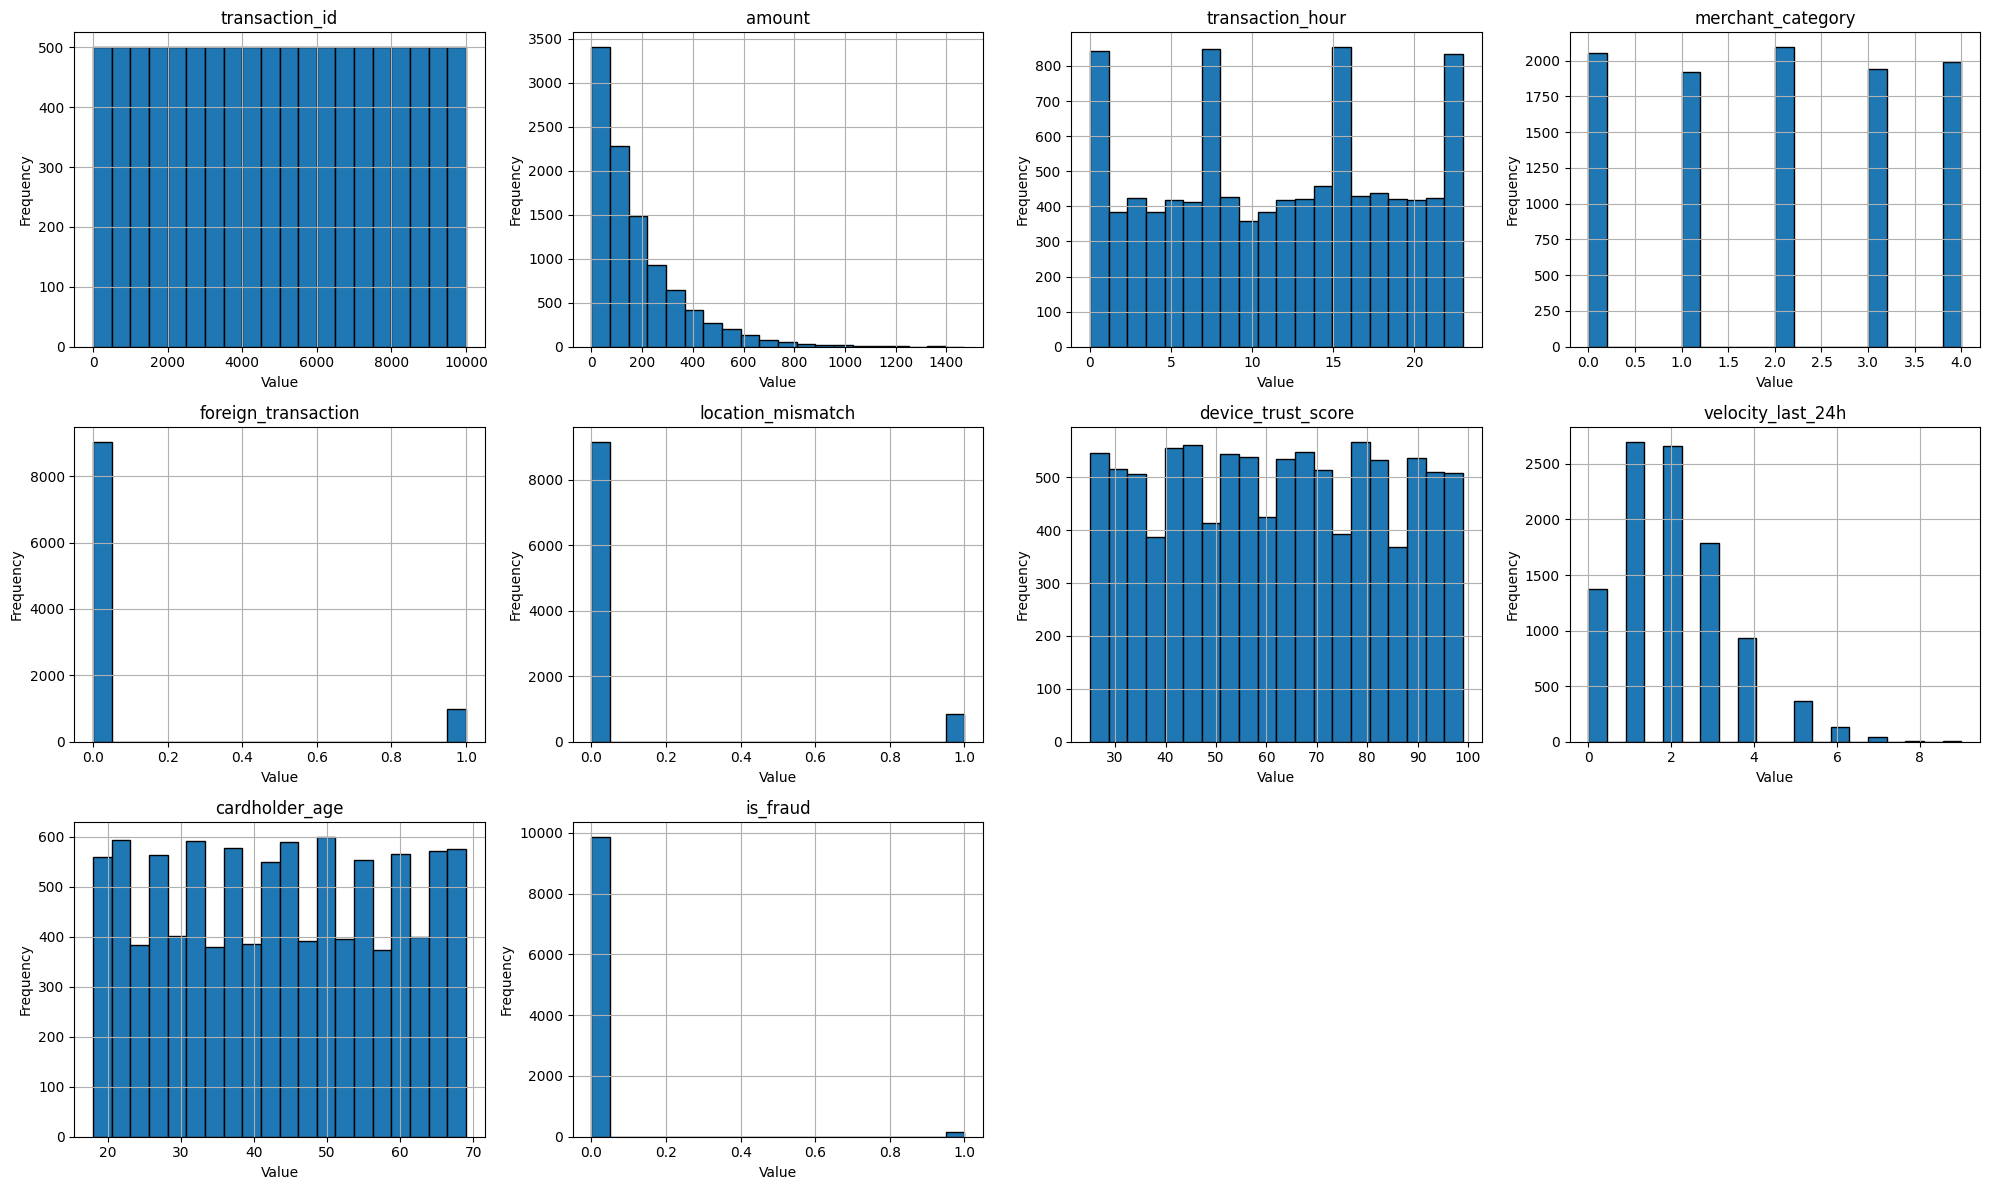

In [63]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah kolom dan baris grafik
n_cols = 4
n_rows = -(-num_vars // n_cols)

# Membuat subplot
fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(20, n_rows * 4)
)

# Meratakan axes agar mudah digunakan
axes = axes.flatten()

# Membuat histogram setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(
        ax=axes[i],
        bins=20,
        edgecolor="black"
    )

    axes[i].set_title(column)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")

# Menghapus grafik kosong
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

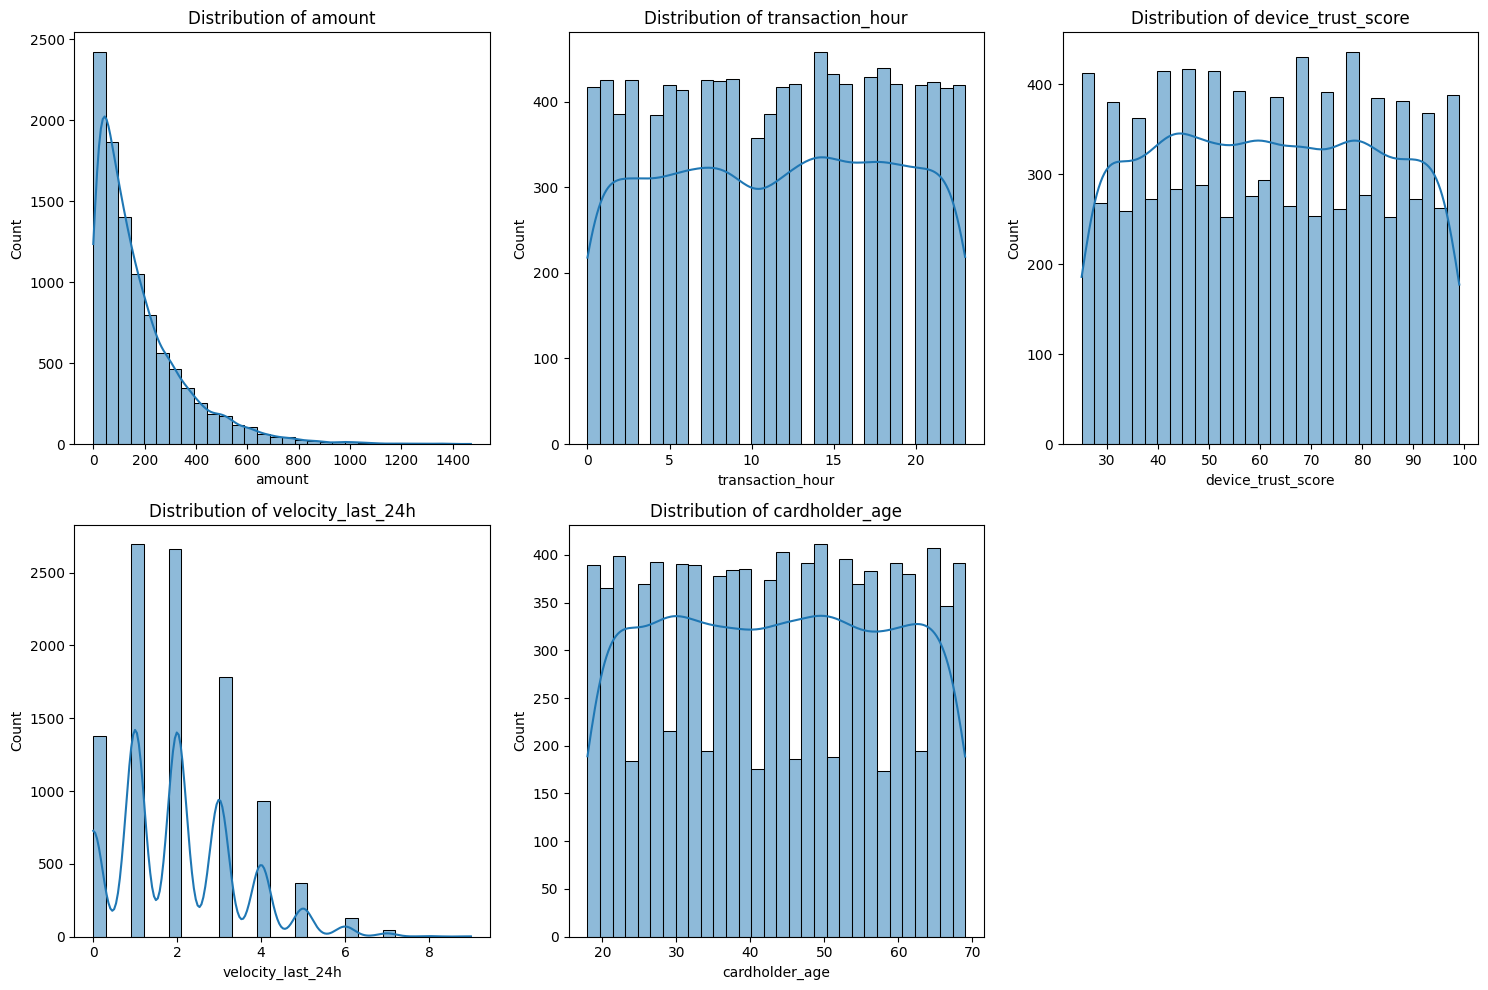

In [64]:
# Kolom yang akan divisualisasikan
columns_to_plot = [
    "amount",
    "transaction_hour",
    "device_trust_score",
    "velocity_last_24h",
    "cardholder_age"
]

# Membuat histogram
plt.figure(figsize=(15, 10))

for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)

    sns.histplot(df[column], kde=True, bins=30)

    plt.title(f"Distribution of {column}")

plt.tight_layout()
plt.show()

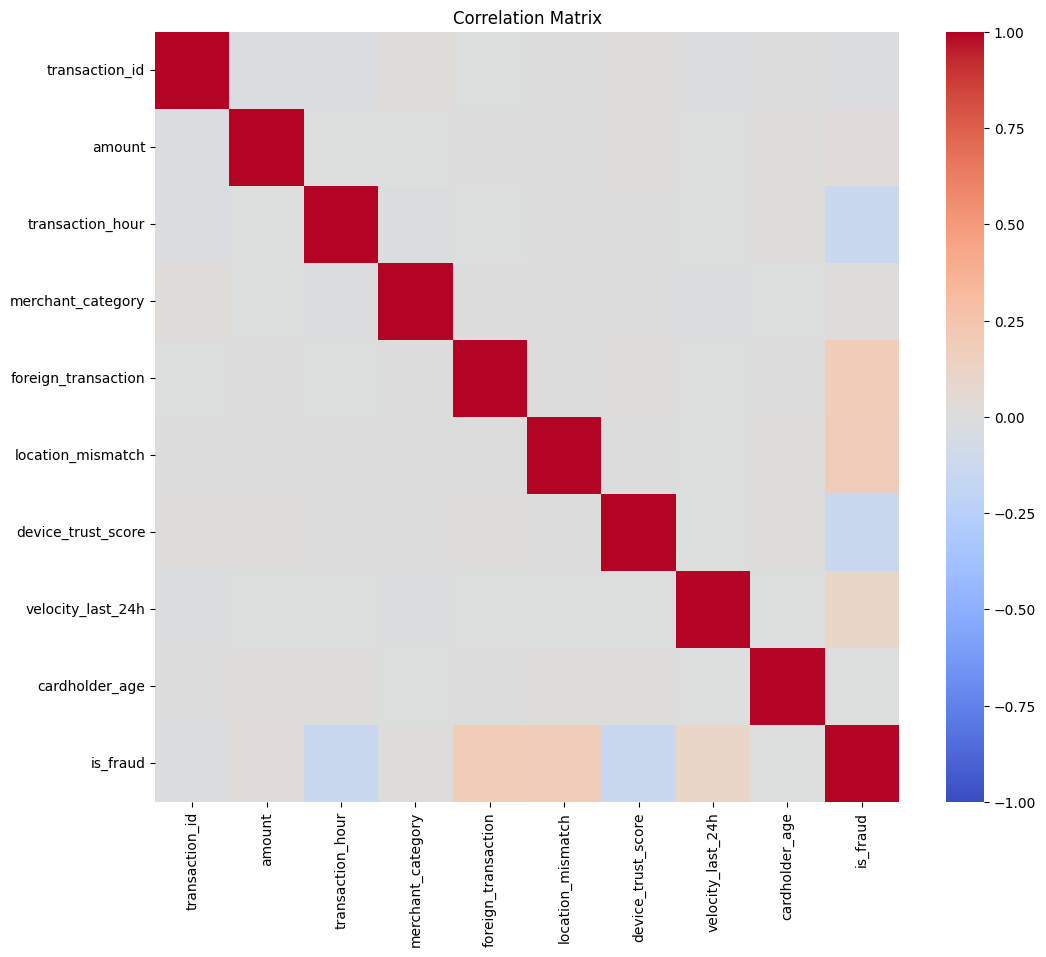

In [65]:
s# Menghitung korelasi dari data hasil Label Encoding
correlation_matrix = df_lencoder.corr(
    numeric_only=True
)

# Membuat heatmap korelasi
plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation_matrix,
    annot=False,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix")
plt.show()

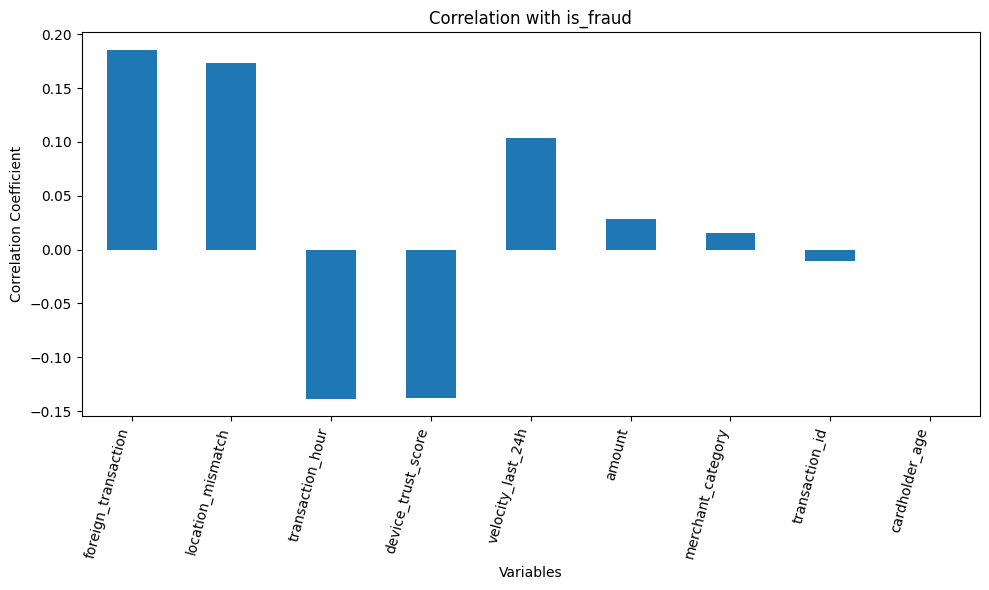

In [66]:
# Menghitung korelasi terhadap target is_fraud
target_corr = correlation_matrix["is_fraud"].drop(
    "is_fraud"
)

# Mengurutkan berdasarkan besar korelasi absolut
target_corr_sorted = target_corr.reindex(
    target_corr.abs().sort_values(
        ascending=False
    ).index
)

# Membuat grafik korelasi
plt.figure(figsize=(10, 6))

target_corr_sorted.plot(kind="bar")

plt.title("Correlation with is_fraud")
plt.xlabel("Variables")
plt.ylabel("Correlation Coefficient")
plt.xticks(rotation=75, ha="right")

plt.tight_layout()
plt.show()

In [67]:
# Memisahkan fitur dan target
X = df_one_hot.drop(
    columns=["is_fraud", "transaction_id"]
)

y = df_one_hot["is_fraud"]

# Menampilkan jumlah data
print("Jumlah data:", len(X))
print("Jumlah fitur:", X.shape[1])
print("Jumlah target:", len(y))

Jumlah data: 10000
Jumlah fitur: 12
Jumlah target: 10000


In [68]:
from sklearn.model_selection import train_test_split

# Membagi dataset menjadi data latih dan data uji
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1,
    stratify=y
)

# Menampilkan jumlah data
print("Jumlah data:", len(X))
print("Jumlah data latih:", len(x_train))
print("Jumlah data test:", len(x_test))

Jumlah data: 10000
Jumlah data latih: 8000
Jumlah data test: 2000


In [69]:
from sklearn.preprocessing import StandardScaler

# Kolom numerik asli yang perlu distandardisasi
numeric_to_scale = [
    "amount",
    "transaction_hour",
    "device_trust_score",
    "velocity_last_24h",
    "cardholder_age"
]

# Menyesuaikan scaler hanya dengan data training
scaler = StandardScaler()

x_train = x_train.copy()
x_test = x_test.copy()

x_train[numeric_to_scale] = scaler.fit_transform(
    x_train[numeric_to_scale]
)

# Data testing hanya ditransformasi, bukan di-fit ulang
x_test[numeric_to_scale] = scaler.transform(
    x_test[numeric_to_scale]
)

x_train.head()

,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,merchant_category_Clothing,merchant_category_Electronics,merchant_category_Food,merchant_category_Grocery,merchant_category_Travel
5847,0.365037,1.069067,0,0,-1.299732,-1.397361,0.374714,0,0,1,0,0
7259,-0.400601,0.492226,0,0,0.428713,2.802335,1.041881,0,0,0,1,0
4100,0.021432,0.492226,0,0,-1.673450,0.702487,-0.359169,0,1,0,0,0
1995,0.095401,1.069067,0,0,0.475427,1.402436,0.041131,1,0,0,0,0
4789,-0.593125,0.924857,0,0,-1.580021,0.002537,-1.359920,1,0,0,0,0


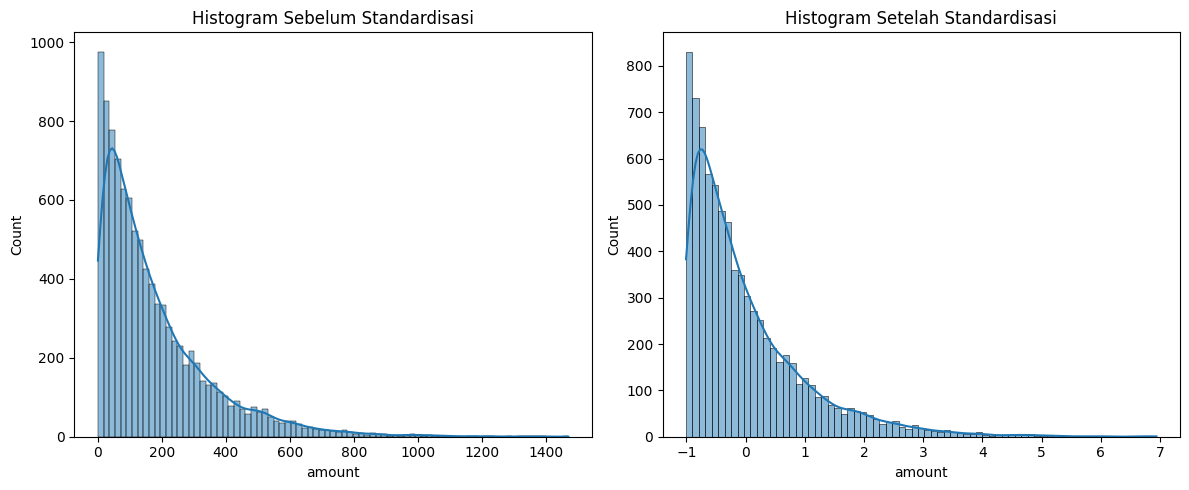

In [70]:
# Contoh melihat distribusi amount setelah standardisasi
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df["amount"], kde=True)
plt.title("Histogram Sebelum Standardisasi")

plt.subplot(1, 2, 2)
sns.histplot(x_train["amount"], kde=True)
plt.title("Histogram Setelah Standardisasi")

plt.tight_layout()
plt.show()

In [71]:
from sklearn.linear_model import LogisticRegression

# Melatih model Logistic Regression
LR = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=1
)

LR.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`

In [72]:
from sklearn.ensemble import RandomForestClassifier

# Melatih model Random Forest
RF = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=1
)

RF.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [73]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Prediksi menggunakan Logistic Regression
pred_LR = LR.predict(x_test)

# Menghitung evaluasi
accuracy_LR = accuracy_score(y_test, pred_LR)
precision_LR = precision_score(
    y_test, pred_LR, zero_division=0
)
recall_LR = recall_score(
    y_test, pred_LR, zero_division=0
)
f1_LR = f1_score(
    y_test, pred_LR, zero_division=0
)

# Menyimpan hasil evaluasi
data = {
    "Accuracy": [accuracy_LR],
    "Precision": [precision_LR],
    "Recall": [recall_LR],
    "F1-score": [f1_LR]
}

df_results = pd.DataFrame(
    data,
    index=["Logistic Regression"]
)

df_results

,Accuracy,Precision,Recall,F1-score
Logistic Regression,0.9595,0.27027,1.0,0.425532


In [74]:
# Prediksi menggunakan Random Forest
pred_RF = RF.predict(x_test)

# Menghitung evaluasi
accuracy_RF = accuracy_score(y_test, pred_RF)
precision_RF = precision_score(
    y_test, pred_RF, zero_division=0
)
recall_RF = recall_score(
    y_test, pred_RF, zero_division=0
)
f1_RF = f1_score(
    y_test, pred_RF, zero_division=0
)

# Menambahkan hasil ke tabel evaluasi
df_results.loc["Random Forest"] = [
    accuracy_RF,
    precision_RF,
    recall_RF,
    f1_RF
]

df_results

,Accuracy,Precision,Recall,F1-score
Logistic Regression,0.9595,0.27027,1.000000,0.425532
Random Forest,0.9905,1.00000,0.366667,0.536585


In [75]:
# Menampilkan hasil evaluasi seluruh model
df_results

,Accuracy,Precision,Recall,F1-score
Logistic Regression,0.9595,0.27027,1.000000,0.425532
Random Forest,0.9905,1.00000,0.366667,0.536585


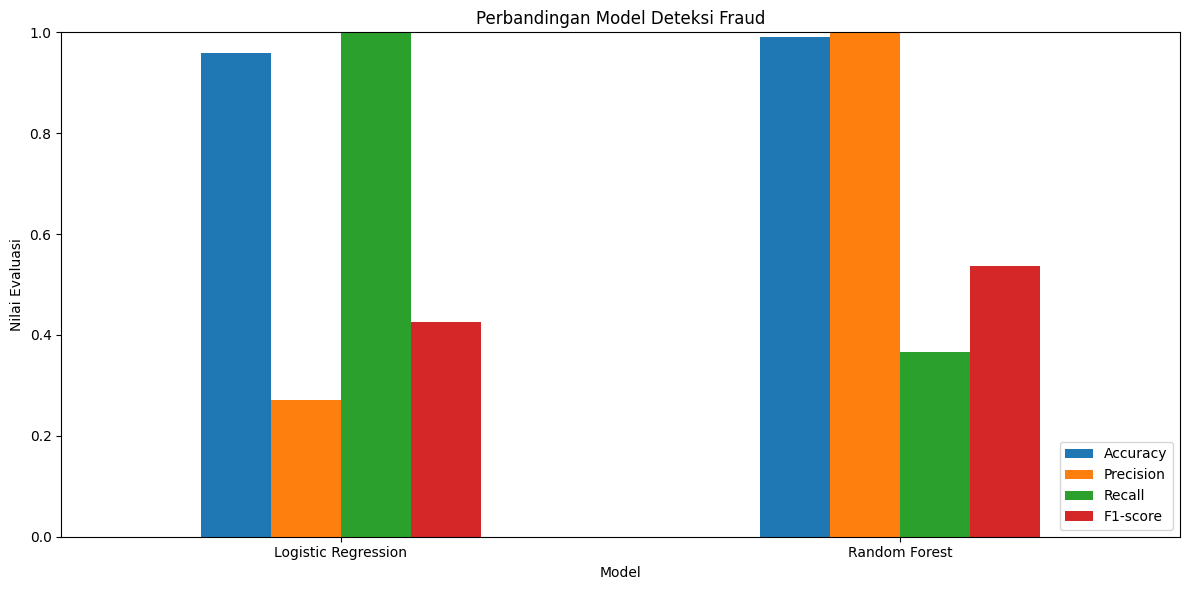

In [83]:
# Membuat grafik perbandingan hasil evaluasi
df_results.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Perbandingan Model Deteksi Fraud")
plt.xlabel("Model")
plt.ylabel("Nilai Evaluasi")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [84]:
from sklearn.metrics import classification_report

# Evaluasi detail untuk Random Forest
print(
    classification_report(
        y_test,
        pred_RF,
        target_names=["Bukan Fraud", "Fraud"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

 Bukan Fraud       0.99      1.00      1.00      1970
       Fraud       1.00      0.37      0.54        30

    accuracy                           0.99      2000
   macro avg       1.00      0.68      0.77      2000
weighted avg       0.99      0.99      0.99      2000



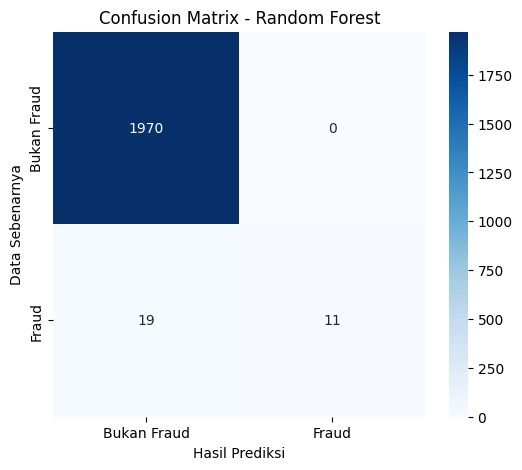

In [85]:
from sklearn.metrics import confusion_matrix

# Menghitung confusion matrix
cm = confusion_matrix(y_test, pred_RF)

# Membuat visualisasi
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Bukan Fraud", "Fraud"],
    yticklabels=["Bukan Fraud", "Fraud"]
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Hasil Prediksi")
plt.ylabel("Data Sebenarnya")
plt.show()

In [86]:
# Menghitung jumlah setiap kelas
print("Jumlah transaksi:", len(df))
print(
    "Jumlah transaksi fraud:",
    int((df["is_fraud"] == 1).sum())
)
print(
    "Jumlah transaksi bukan fraud:",
    int((df["is_fraud"] == 0).sum())
)

# Menghitung persentase fraud
persentase_fraud = df["is_fraud"].mean() * 100

print(
    "Persentase transaksi fraud: {:.2f}%".format(
        persentase_fraud
    )
)

Jumlah transaksi: 10000
Jumlah transaksi fraud: 151
Jumlah transaksi bukan fraud: 9849
Persentase transaksi fraud: 1.51%


In [87]:
import joblib

# Menyimpan model Random Forest
joblib.dump(RF, "random_forest_model.joblib")

['random_forest_model.joblib']

In [88]:
import pickle

# Menyimpan model Random Forest
with open("random_forest_model.pkl", "wb") as file:
    pickle.dump(RF, file)

In [89]:
# Menyimpan scaler
joblib.dump(scaler, "scaler.joblib")

# Menyimpan susunan kolom fitur
joblib.dump(list(x_train.columns), "feature_columns.joblib")

['feature_columns.joblib']